# 03 Exploratory data analysis (dev set only)

**Input:** `data/processed/features.parquet` from notebook 02.
**Scope:** only the development set (set-a + set-b, `split == "dev"`, 8,000 stays). The test set (set-c) is not looked at, so nothing we see here can bias the final evaluation.

## Questions
1. How imbalanced is the outcome?
2. Who dies? Mortality by age, gender and ICU type
3. What is missing, what goes missing together, and does missingness predict death?
4. Which single features separate deaths from survivors best?
5. Which features are redundant?
6. What do the 13 stays with no measurements look like?

Figures are saved to `reports/figures/03_*.png`.

In [1]:
# ── Cell 1: setup, load the dev set ─────────────────────────────────
# INSIGHTS
# - Only split == "dev" rows are kept. The test rows are dropped right after loading
#   and never used in this notebook.
# - Result: 8,000 dev stays (set-a and set-b only), 225 features, 36 time-series variables.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

LABEL = "In-hospital_death"
NON_FEATURES = ["RecordID", "set", "split", "fold", LABEL, "SAPS-I", "SOFA"]
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

table = pd.read_parquet(PROCESSED / "features.parquet")
dev = table[table["split"] == "dev"].reset_index(drop=True)
del table  # make sure the test rows cannot be used by accident
FEATURES = [c for c in dev.columns if c not in NON_FEATURES]
VARS = sorted(c[4:] for c in FEATURES if c.startswith("has_"))
y = dev[LABEL]
print(f"Dev set: {len(dev):,} stays, {len(FEATURES)} features, {len(VARS)} time-series variables")
print("Sets in dev:", sorted(dev["set"].unique()))


def wilson(k, n, z=1.96):
    """Wilson 95% interval for a proportion k/n. Better than p +/- 1.96*se for small n or p near 0."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(groups):
    """Mortality per group with Wilson CI, as percentages."""
    g = dev.groupby(groups, observed=True)[LABEL].agg(stays="size", deaths="sum")
    lo, hi = wilson(g["deaths"], g["stays"])
    g["mortality_%"] = (g["deaths"] / g["stays"] * 100).round(1)
    g["ci_95_%"] = [f"[{a*100:.1f}, {b*100:.1f}]" for a, b in zip(lo, hi)]
    return g

Dev set: 8,000 stays, 225 features, 36 time-series variables
Sets in dev: ['a', 'b']


In [2]:
# ── Cell 2: class balance and the accuracy trap ────────────────────
# INSIGHTS
# - The outcome is imbalanced: deaths are the minority class.
# - A "model" that predicts survival for everyone gets accuracy = 1 - mortality, while
#   finding zero deaths. That is why we use AUROC / AUPRC and not accuracy.
# - For modeling: use class weights (or just rely on ranking metrics) rather than
#   oversampling, and keep folds stratified.
# - Result: 6,878 survived, 1,122 died: 14.03% mortality, 6.1 survivors per death.
#   Predicting "survives" for everyone gives 85.97% accuracy and finds 0 deaths.
#   AUPRC floor = 0.140.
counts = y.value_counts().rename({0: "survived", 1: "died"})
print(counts.to_string())
print(f"Mortality: {y.mean():.2%}   ratio survivors:deaths = {counts['survived'] / counts['died']:.1f} : 1")
print(f"Accuracy of 'everyone survives': {1 - y.mean():.2%}  (finds 0 of {counts['died']} deaths)")
print(f"AUPRC of a random model (the floor): {y.mean():.3f}")

In-hospital_death
survived    6878
died        1122
Mortality: 14.03%   ratio survivors:deaths = 6.1 : 1
Accuracy of 'everyone survives': 85.97%  (finds 0 of 1122 deaths)
AUPRC of a random model (the floor): 0.140


Age: min 15.0  max 90.0  stays at exactly 90: 308  under 18: 14


,stays,deaths,mortality_%,ci_95_%
age_band,,,,
<40,753,58,7.7,"[6.0, 9.8]"
40-59,2138,212,9.9,"[8.7, 11.3]"
60-69,1481,184,12.4,"[10.8, 14.2]"
70-79,1875,272,14.5,"[13.0, 16.2]"
80+,1753,396,22.6,"[20.7, 24.6]"


,stays,deaths,mortality_%,ci_95_%
gender,,,,
female,3493,512,14.7,"[13.5, 15.9]"
male,4499,609,13.5,"[12.6, 14.6]"
unknown,8,1,12.5,"[2.2, 47.1]"


,stays,deaths,mortality_%,ci_95_%
icu_type,,,,
cardiac_surgery,1656,77,4.6,"[3.7, 5.8]"
coronary,1167,153,13.1,"[11.3, 15.2]"
surgical,2260,331,14.6,"[13.2, 16.2]"
medical,2917,561,19.2,"[17.8, 20.7]"


Median age per ICU type: {'cardiac_surgery': 70.0, 'coronary': 73.0, 'medical': 65.0, 'surgical': 63.0}


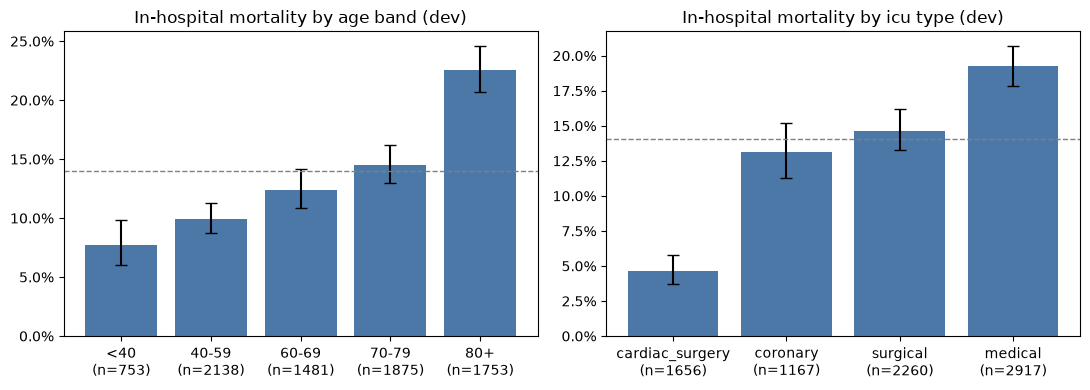

In [3]:
# ── Cell 3: who dies? age, gender, ICU type ─────────────────────────
# INSIGHTS
# - Wilson 95% intervals show how sure each rate is (narrow for big groups).
# - Result: age is capped at 90 (308 stays at exactly 90, an anonymisation cap) and 14
#   stays are under 18 (youngest 15). Mortality rises with age: <40 7.7% [6.0, 9.8],
#   40-59 9.9%, 60-69 12.4%, 70-79 14.5%, 80+ 22.6% [20.7, 24.6]. Gender barely matters
#   (female 14.7%, male 13.5%, CIs overlap). ICU type matters a lot: cardiac surgery
#   4.6% [3.7, 5.8], coronary 13.1%, surgical 14.6%, medical 19.2% [17.8, 20.7].
print("Age: min", dev["Age"].min(), " max", dev["Age"].max(),
      f" stays at exactly 90: {(dev['Age'] == 90).sum()}", f" under 18: {(dev['Age'] < 18).sum()}")
age_band = pd.cut(dev["Age"], [0, 39, 59, 69, 79, 200], labels=["<40", "40-59", "60-69", "70-79", "80+"])
by_age = rate_table(age_band.rename("age_band"))
display(by_age)

gender = dev["Gender"].map({0: "female", 1: "male"}).fillna("unknown").rename("gender")
display(rate_table(gender))

icu_cols = [c for c in dev.columns if c.startswith("ICUType_")]
icu = dev[icu_cols].idxmax(axis=1).str.replace("ICUType_", "").rename("icu_type")
by_icu = rate_table(icu).sort_values("mortality_%")
display(by_icu)
print("Median age per ICU type:", dev.groupby(icu)["Age"].median().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t, title in [(axes[0], by_age, "Age band"), (axes[1], by_icu, "ICU type")]:
    rate = t["deaths"] / t["stays"]
    lo, hi = wilson(t["deaths"], t["stays"])
    ax.bar(range(len(t)), rate, color="#4C78A8",
           yerr=[rate - lo, hi - rate], capsize=4)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(t.index, t["stays"])])
    ax.set_title(f"In-hospital mortality by {title.lower()} (dev)")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.axhline(y.mean(), color="grey", ls="--", lw=1)
plt.tight_layout()
fig.savefig(FIGURES / "03_mortality_by_age_icu.png", dpi=150)
plt.show()

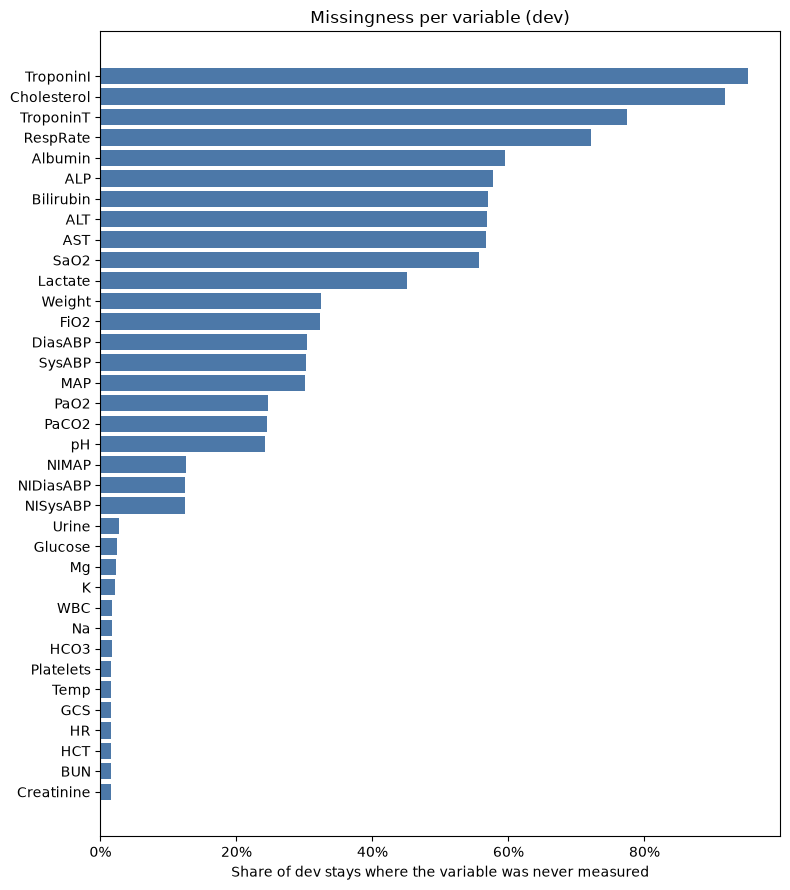

Static columns missing: {'Height': 0.48, 'Weight_admit': 0.084, 'Gender': 0.001}
Variables missing in >50% of stays: 10,  in <5%: 14


In [4]:
# ── Cell 4: how much is missing per variable? ───────────────────────
# INSIGHTS
# - "Missing" = never measured in the 48 h. Labs that are only ordered for a reason
#   (troponins, cholesterol, liver panel, lactate) are missing most often.
# - Result: 10 of 36 variables are never measured in more than half of stays, 14 are
#   missing in under 5%. Height is missing for 48.0%, admission weight 8.4%, gender 0.1%.
miss = pd.Series({v: 1 - dev[f"has_{v}"].mean() for v in VARS}).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(miss.index, miss.values, color="#4C78A8")
ax.set_xlabel("Share of dev stays where the variable was never measured")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Missingness per variable (dev)")
plt.tight_layout()
fig.savefig(FIGURES / "03_missing_rate.png", dpi=150)
plt.show()
print("Static columns missing:", dev[["Height", "Weight_admit", "Gender"]].isna().mean().round(3).to_dict())
print(f"Variables missing in >50% of stays: {(miss > .5).sum()},  in <5%: {(miss < .05).sum()}")

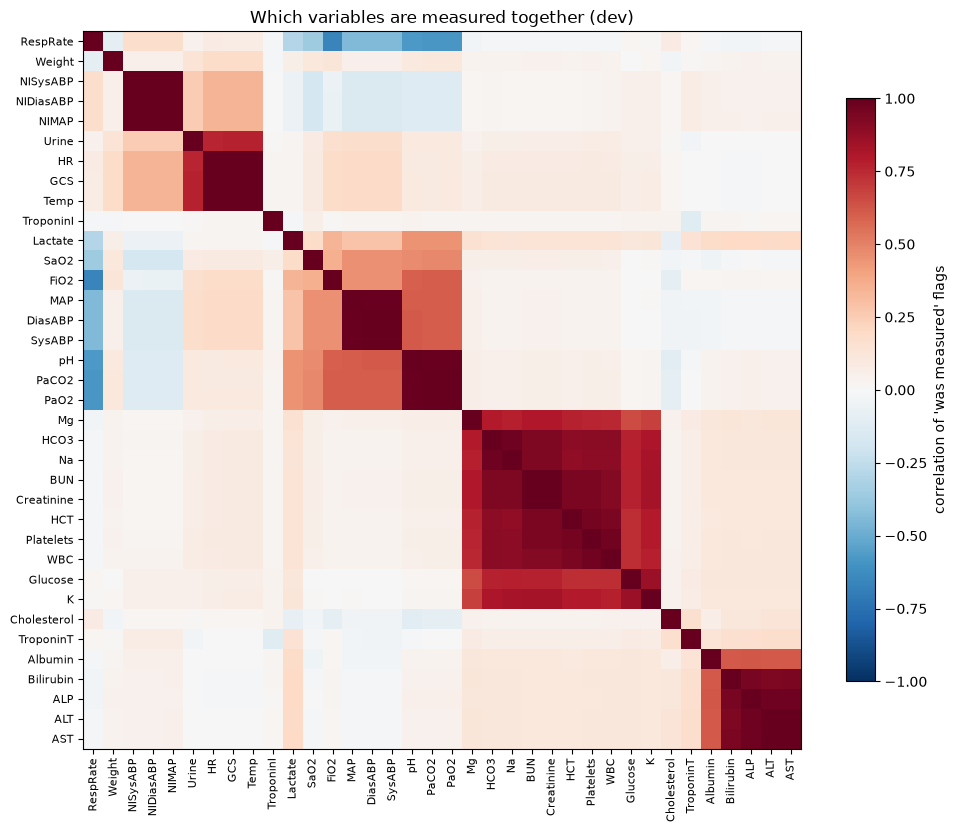

Most strongly measured together:


r
NISysABP  NIDiasABP   0.995
NIDiasABP NIMAP       0.996
HR        Temp        0.996
          GCS         0.996
PaCO2     PaO2        0.998
DiasABP   SysABP      1.000
GCS       Temp        1.000
BUN       Creatinine  1.000

Most strongly 'one or the other':


r
RespRate FiO2  -0.662
         PaCO2 -0.580
         PaO2  -0.579
         pH    -0.573
         MAP   -0.443

In [5]:
# ── Cell 5: what goes missing together? ─────────────────────────────
# INSIGHTS
# - Correlation of the has_ flags: +1 = always measured together (one lab panel),
#   -1 = one replaces the other.
# - Invasive arterial BP (SysABP...) vs non-invasive cuff BP (NISysABP...) should be
#   negatively related: a patient with an arterial line rarely needs the cuff.
# - Result: clear blocks: the routine labs (BUN, Creatinine, HCO3, Na, K...) are measured
#   together, as are the blood gas (pH, PaO2, PaCO2), the liver panel (ALT, AST, ALP,
#   Bilirubin), invasive BP (SysABP/DiasABP/MAP, r = 1.0) and cuff BP (r about 0.99).
#   The strongest "one or the other" is RespRate vs FiO2 (r = -0.66): RespRate is mostly
#   charted for patients who are NOT on a ventilator, FiO2/blood gases for those who are.
has = dev[[f"has_{v}" for v in VARS]].rename(columns=lambda c: c[4:])
has = has.loc[:, has.std() > 0]
corr = has.corr()

# order variables by hierarchical clustering so blocks are visible
from scipy.cluster.hierarchy import linkage, leaves_list
order = leaves_list(linkage(1 - corr.values[np.triu_indices(len(corr), 1)], "average"))
corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.7, label="correlation of 'was measured' flags")
ax.set_title("Which variables are measured together (dev)")
plt.tight_layout()
fig.savefig(FIGURES / "03_missingness_clusters.png", dpi=150)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().dropna().sort_values()
print("Most strongly measured together:")
display(pairs.tail(8).round(3).to_frame("r"))
print("Most strongly 'one or the other':")
display(pairs.head(5).round(3).to_frame("r"))

In [6]:
# ── Cell 6: missingness by ICU type, and does it predict death? ─────
# INSIGHTS
# - Different units order different tests, so missingness also encodes the type of patient.
# - For every variable: mortality when measured vs never measured. A large gap means the
#   has_ flag is useful on its own.
# - Result: units order differently: cardiac surgery almost always has blood gases
#   (pH missing 4.0%) and an arterial line (SysABP missing 4.4%) but rarely liver tests
#   or RespRate (95.1% missing). Medical ICU has the most liver/albumin tests.
#   Mortality is about 2x higher when lactate, pH, blood gases, liver tests, albumin or
#   troponins were measured. For routine labs (WBC, BUN...) it flips: the ~2% of stays
#   with NO routine labs have only 3-5% mortality. RespRate also flips (7.6% when
#   measured vs 16.5% not), because it is charted for the non-ventilated patients.
miss_icu = (1 - dev.groupby(icu)[[f"has_{v}" for v in VARS]].mean()).T
miss_icu.index = [i[4:] for i in miss_icu.index]
show = ["Lactate", "TroponinT", "TroponinI", "Albumin", "ALT", "pH", "PaO2", "SysABP", "NISysABP", "RespRate", "Cholesterol"]
display((miss_icu.loc[show] * 100).round(1).rename_axis("% never measured"))

rows = []
for v in VARS:
    m = dev[f"has_{v}"] == 1
    if m.all() or (~m).all():
        continue
    rows.append({"variable": v, "measured_%": m.mean() * 100,
                 "mortality_%_measured": y[m].mean() * 100,
                 "mortality_%_not_measured": y[~m].mean() * 100})
mm = pd.DataFrame(rows)
mm["ratio"] = mm["mortality_%_measured"] / mm["mortality_%_not_measured"]
mm = mm.sort_values("ratio", ascending=False).round(2).reset_index(drop=True)
display(mm)

icu_type,cardiac_surgery,coronary,medical,surgical
% never measured,,,,
Lactate,50.8,59.4,43.4,35.4
TroponinT,93.7,56.6,72.3,82.9
TroponinI,97.3,90.8,94.8,96.4
Albumin,83.3,56.0,46.4,60.5
ALT,77.7,47.6,45.6,60.6
pH,4.0,36.2,33.4,20.8
PaO2,4.5,36.2,33.7,21.5
SysABP,4.4,32.3,52.5,19.6
NISysABP,24.8,12.7,6.2,11.2


,variable,measured_%,mortality_%_measured,mortality_%_not_measured,ratio
0,WBC,98.26,14.22,2.88,4.94
1,Platelets,98.38,14.21,3.08,4.62
2,HCT,98.45,14.20,3.23,4.40
3,BUN,98.50,14.19,3.33,4.26
4,Creatinine,98.50,14.19,3.33,4.26
5,HCO3,98.29,14.21,3.65,3.89
6,Glucose,97.49,14.28,3.98,3.59
7,Na,98.28,14.19,4.35,3.26
8,K,97.89,14.23,4.73,3.01
9,Mg,97.68,14.24,4.84,2.94


In [7]:
# ── Cell 7: which single features separate deaths from survivors? ───
# INSIGHTS
# - Univariate AUROC: rank all stays by one feature and check how well that ranking
#   separates deaths. No model is fitted, so it is a fair first look.
# - Direction matters: AUROC < 0.5 means LOW values mean higher risk (e.g. GCS).
#   We report strength = max(AUROC, 1 - AUROC) and the direction separately.
# - NaN stays are left out per feature (n_used shows how many remain).
# - Result: GCS_last is the strongest single feature (0.747, low GCS = risk), then
#   GCS_mean 0.694, BUN_last 0.691, Urine_mean 0.690 (low urine = risk), HCO3_last 0.648,
#   Lactate_last 0.639. Counts also rank high (Na_count 0.638, FiO2_count 0.630).
#   GCS_last alone (0.747) already beats SAPS-I on dev (0.661). 10 features above 0.65,
#   44 above 0.60.
uni = []
for f in FEATURES:
    d = dev[[f, LABEL]].dropna()
    if d[f].nunique() < 2 or d[LABEL].nunique() < 2:
        continue
    a = roc_auc_score(d[LABEL], d[f])
    uni.append({"feature": f, "strength": max(a, 1 - a),
                "higher_value_means": "more risk" if a >= 0.5 else "less risk",
                "n_used": len(d)})
uni = pd.DataFrame(uni).sort_values("strength", ascending=False).reset_index(drop=True)
display(uni.head(20).round(3))
print(f"Features with strength > 0.65: {(uni['strength'] > 0.65).sum()},  > 0.60: {(uni['strength'] > 0.60).sum()}")
print("For reference, SAPS-I on dev:", round(roc_auc_score(dev.dropna(subset=["SAPS-I"])[LABEL], dev["SAPS-I"].dropna()), 3))

,feature,strength,higher_value_means,n_used
0,GCS_last,0.747,less risk,7871
1,GCS_mean,0.694,less risk,7871
2,BUN_last,0.691,more risk,7880
3,Urine_mean,0.690,less risk,7787
4,BUN_min,0.681,more risk,7880
5,BUN_mean,0.681,more risk,7880
6,GCS_max,0.678,less risk,7871
7,BUN_max,0.677,more risk,7880
8,Urine_max,0.671,less risk,7787
9,Urine_last,0.654,less risk,7787


Features with strength > 0.65: 10,  > 0.60: 44
For reference, SAPS-I on dev: 0.661


,feature,strength,higher_value_means
0,GCS_last,0.747,less risk
2,BUN_last,0.691,more risk
3,Urine_mean,0.690,less risk
10,HCO3_last,0.648,less risk
11,Lactate_last,0.639,more risk
16,Creatinine_max,0.626,more risk
23,Age,0.615,more risk
24,Albumin_min,0.614,less risk
26,Glucose_max,0.610,more risk
29,RespRate_max,0.609,more risk


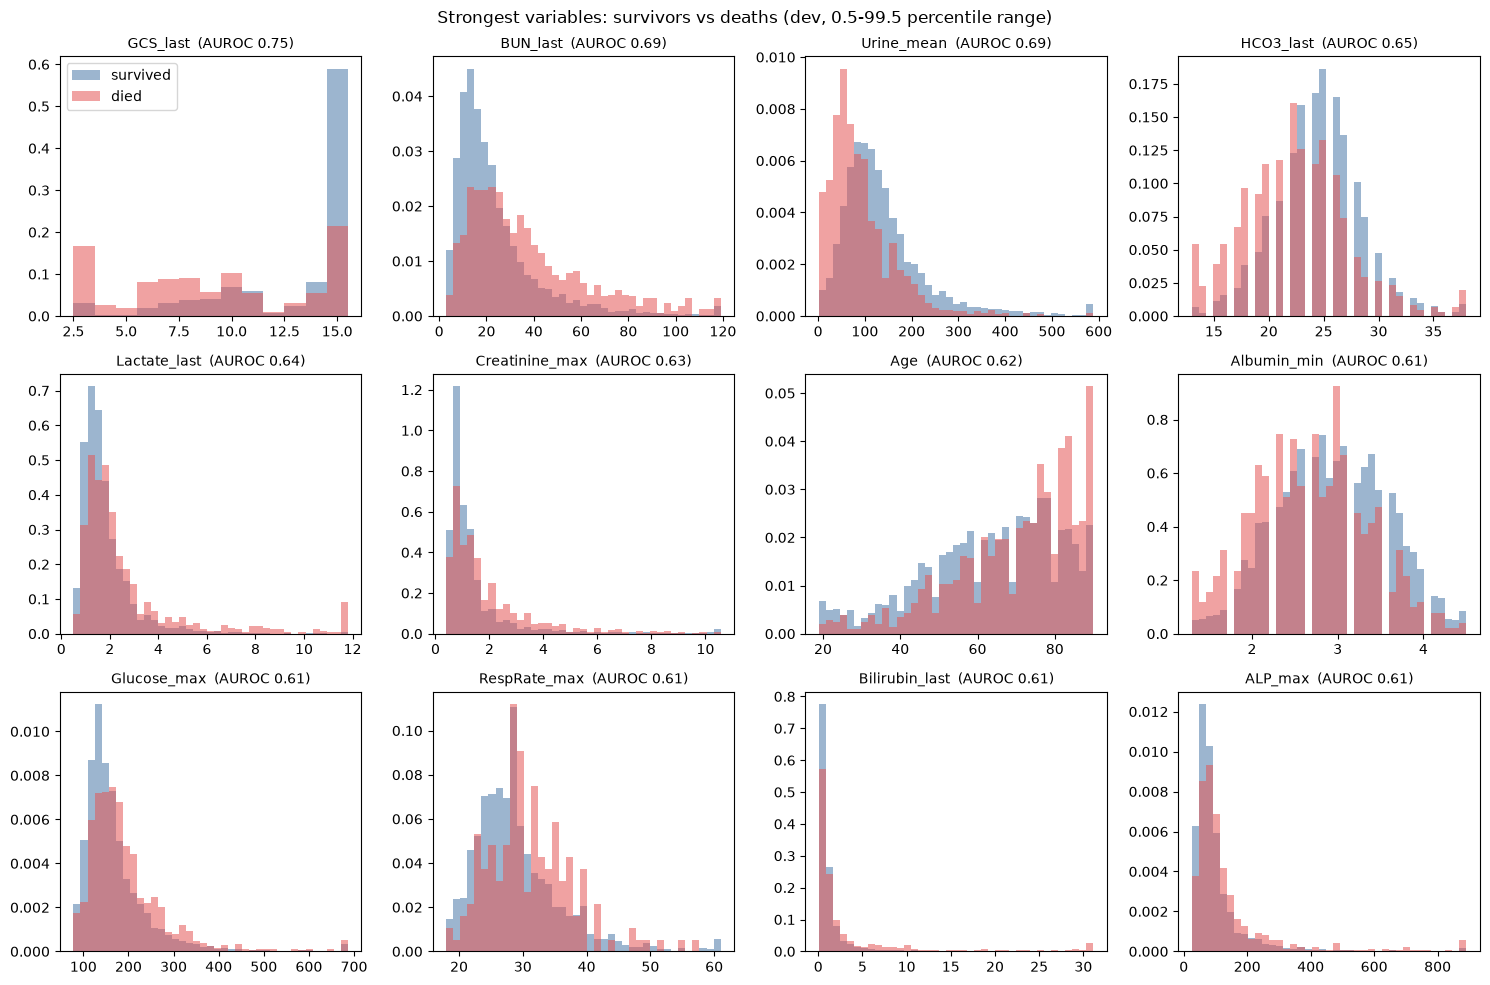

Most right-skewed variables (mean per stay):


,skewness
WBC_mean,73.2
ALT_mean,8.5
AST_mean,8.3
Urine_mean,7.5
Bilirubin_mean,5.9
ALP_mean,5.3
TroponinT_mean,4.7
Creatinine_mean,4.0
MAP_mean,3.7
Lactate_mean,3.3


In [8]:
# ── Cell 8: distributions for the strongest variables ───────────────
# INSIGHTS
# - One panel per variable, taking the strongest feature of each of the 12 strongest
#   variables. Survivors vs deaths, each normalised to its own group size.
# - Skewed variables (long right tail) will need a log transform for logistic regression.
#   Tree models do not care about scale or skew.
# - Result: deaths have lower GCS, higher BUN, less urine, lower HCO3, higher lactate.
#   The "last" value is often stronger than min/max (GCS_last 0.747 vs GCS_max 0.678),
#   so the state at 48 h matters. Strongly right-skewed: WBC (73.2), ALT, AST, Urine,
#   Bilirubin, ALP, TroponinT, Creatinine, so logistic regression needs log transforms.
uni["variable"] = uni["feature"].str.replace(r"^has_", "", regex=True).str.rsplit("_", n=1).str[0]
uni.loc[uni["feature"].isin(["Age", "Gender", "Height", "Weight_admit", "MechVent_ever"]) |
        uni["feature"].str.startswith("ICUType_"), "variable"] = uni["feature"]
top = (uni[~uni["feature"].str.startswith("has_") & ~uni["feature"].str.endswith("_count")]
       .drop_duplicates("variable").head(12))
display(top[["feature", "strength", "higher_value_means"]].round(3))

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, f in zip(axes.ravel(), top["feature"]):
    x = dev[f]
    lo, hi = x.quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 40) if x.nunique() > 20 else np.arange(x.min() - 0.5, x.max() + 1.5)
    for lab, colour, name in [(0, "#4C78A8", "survived"), (1, "#E45756", "died")]:
        ax.hist(x[y == lab].dropna().clip(lo, hi), bins=bins, density=True, alpha=0.55,
                color=colour, label=name)
    ax.set_title(f"{f}  (AUROC {top.set_index('feature').loc[f, 'strength']:.2f})", fontsize=10)
axes[0, 0].legend()
plt.suptitle("Strongest variables: survivors vs deaths (dev, 0.5-99.5 percentile range)")
plt.tight_layout()
fig.savefig(FIGURES / "03_top_distributions.png", dpi=150)
plt.show()

means = [f"{v}_mean" for v in VARS if f"{v}_mean" in dev]
skew = dev[means].skew().sort_values(ascending=False)
print("Most right-skewed variables (mean per stay):")
display(skew.head(10).round(1).to_frame("skewness"))

In [9]:
# ── Cell 9: redundancy between features ─────────────────────────────
# INSIGHTS
# - Pairs with |r| > 0.9 carry almost the same information (e.g. HR_mean vs HR_last,
#   NIMAP vs NISysABP). Trees cope fine; for logistic regression this makes coefficients
#   unstable, so regularisation (L2) is needed. Nothing is dropped yet.
# - has_<var> and <var>_count = 0 are the same information by construction.
# - Result: 97 pairs with |r| > 0.9 out of 35,721. 74 are within one variable (e.g.
#   min vs mean). Of the 23 across variables, almost all are counts of tests done
#   together (SysABP_count vs DiasABP_count r = 1.000, ALT_count vs AST_count 0.998).
#   Only one is a value pair (NIDiasABP_max vs NIMAP_max 0.911).
num = dev[[f for f in FEATURES if not f.startswith("has_")]]
num = num.loc[:, num.std() > 0]
c = num.corr().abs()
pairs = c.where(np.triu(np.ones(c.shape, bool), 1)).stack().dropna()
high = pairs[pairs > 0.9].sort_values(ascending=False)
print(f"Feature pairs with |r| > 0.9: {len(high)} (of {len(pairs):,} pairs)")
same_var = sum(a.rsplit('_', 1)[0] == b.rsplit('_', 1)[0] for a, b in high.index)
print(f"  of which within the same variable (e.g. min vs mean): {same_var}")
print(f"  across different variables: {len(high) - same_var}")
cross = high[[a.rsplit('_', 1)[0] != b.rsplit('_', 1)[0] for a, b in high.index]]
display(cross.round(3).to_frame("|r|"))

Feature pairs with |r| > 0.9: 97 (of 17,738 pairs)
  of which within the same variable (e.g. min vs mean): 74
  across different variables: 23


,,|r|
DiasABP_count,SysABP_count,1.000
NIDiasABP_count,NISysABP_count,1.000
PaCO2_count,PaO2_count,0.999
ALT_count,AST_count,0.998
NIDiasABP_count,NIMAP_count,0.997
NIMAP_count,NISysABP_count,0.997
BUN_count,Creatinine_count,0.993
PaCO2_count,pH_count,0.993
PaO2_count,pH_count,0.992
ALP_count,AST_count,0.988


In [10]:
# ── Cell 10: the stays with no measurements at all ──────────────────
# INSIGHTS
# - These stays have descriptors (age, ICU type) but not a single vital sign or lab.
# - Result: 10 dev stays have no time-series data, all survivors, all with SAPS-I and
#   SOFA missing too, mostly medical/coronary, mostly no height or weight. They look like
#   records that were never filled in, not real ICU stays. Recommendation: exclude them
#   from training and report them separately (the same rule for the 3 in set-c), because
#   a model could learn the artefact "no data = survives".
cnt_cols = [f"{v}_count" for v in VARS]
empty = dev[dev[cnt_cols].sum(axis=1) == 0]
print(f"Dev stays with no time-series data: {len(empty)}  (deaths: {empty[LABEL].sum()})")
display(empty[["RecordID", "set", "Age", "Gender", "Height", "Weight_admit", "MechVent_ever", "SAPS-I", "SOFA", LABEL]]
        .assign(icu=icu[empty.index]))

Dev stays with no time-series data: 10  (deaths: 0)


,RecordID,set,Age,Gender,Height,Weight_admit,MechVent_ever,SAPS-I,SOFA,In-hospital_death,icu
3147,140501,a,31.0,1.0,NaN,NaN,0,NaN,NaN,0,medical
3307,140936,a,49.0,1.0,NaN,NaN,0,NaN,NaN,0,medical
3437,141264,a,90.0,0.0,NaN,NaN,0,NaN,NaN,0,medical
4028,142731,b,58.0,1.0,NaN,NaN,0,NaN,NaN,0,medical
4128,142998,b,22.0,0.0,NaN,NaN,0,NaN,NaN,0,cardiac_surgery
4396,143656,b,45.0,1.0,182.9,75.0,0,NaN,NaN,0,coronary
5158,145611,b,49.0,1.0,NaN,NaN,0,NaN,NaN,0,medical
5917,147514,b,49.0,1.0,NaN,NaN,0,NaN,NaN,0,cardiac_surgery
7007,150309,b,32.0,1.0,NaN,NaN,0,NaN,NaN,0,coronary
7139,150649,b,74.0,1.0,NaN,NaN,0,NaN,NaN,0,coronary


## Summary

**Data**
- 8,000 dev stays, 1,122 deaths (14.0%). Predicting "survives" for everyone is 86% accurate and useless, so we use AUROC/AUPRC (floor 0.140).
- Age is capped at 90 (308 stays) and 14 patients are 15 to 17 years old. 10 dev stays have no measurements at all (all survivors, no SAPS-I either).

**Who dies**
- Mortality rises with age, from 7.7% under 40 to 22.6% at 80+.
- ICU type matters most among the static fields: cardiac surgery recovery 4.6%, medical ICU 19.2%. Gender makes almost no difference.

**Missingness**
- It comes in blocks (routine labs, blood gas, liver panel, invasive vs cuff BP) and depends on the ICU type.
- Mortality is about twice as high when lactate, blood gases, liver tests, albumin or troponins were measured. The few stays with no routine labs at all have very low mortality (3 to 5%).
- RespRate is the reverse (7.6% measured vs 16.5% not), because it is mostly charted for patients who are not on a ventilator.

**Strongest single features (univariate AUROC)**
- GCS_last 0.747, GCS_mean 0.694, BUN_last 0.691, Urine_mean 0.690, HCO3_last 0.648, Lactate_last 0.639.
- GCS_last alone beats SAPS-I on dev (0.661). The value at 48 h ("last") is often stronger than the worst value.

**Redundancy**
- 97 feature pairs with |r| > 0.9, mostly the same variable's min/mean/last, or counts of tests done together.

**Implications for modeling**
1. Gradient boosting (LightGBM/XGBoost) can use NaN directly and does not care about skew or correlation. It is the most promising model family.
2. Logistic regression needs, inside the CV pipeline: median imputation, the `has_` flags, a log transform for skewed variables (WBC, liver tests, urine, creatinine, lactate), scaling, and L2 regularisation for the correlated features.
3. Handle the imbalance with class weights or simply rank-based metrics, with stratified folds. No oversampling.
4. Exclude the 13 empty stays (10 dev, 3 test) and report them separately.
5. Check performance by ICU type and age band in Phase 5, because the base rates differ so much.

**Next:** `04_modeling.ipynb`: logistic regression baseline, then random forest and gradient boosting, compared against SAPS-I with 5-fold CV on the dev set.